# Equation discovery for wind — the wake decay law and the erosion law

Two wind discoveries from data, with no model assumed:
1. the **wake decay law** --- how the centreline deficit falls with downstream distance,
2. **closing the hybrid loop** --- a hybrid turbine model has learned the torque lost to blade erosion as a
   neural-network correction; sparse regression on that correction recovers the **erosion law** as an explicit
   equation.

Both use sparse regression (STLSQ) over a small candidate library, exactly as for the vessel ---
turning learned corrections and raw measurements back into interpretable physics.

The prose narrates the **default** run. Change the values below and *Run All*; every figure follows.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
U_INF, NU_T = 8.0, 0.5           # free-stream speed [m/s] and eddy viscosity of the wake model
X_MIN, X_MAX, N_X = 1.0, 8.0, 60 # downstream sampling of the centreline deficit
WAKE_NOISE, LAM_WAKE = 0.04, 0.6 # multiplicative noise and STLSQ threshold for the decay law
ENS_B, ENS_NOISE, ENS_LAM = 200, 0.08, 0.5   # ensemble: resamples, noise, threshold
EROSION_SLOPE, EROSION_NOISE, LAM_EROSION = 0.015, 0.05, 0.14   # erosion law delta = slope * lambda (tip-speed ratio)
# --------------------------------------------------------------------------

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
np.random.seed(0)
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg

def stlsq(Theta, y, lam, n_iter=20):
    norm = np.linalg.norm(Theta, axis=0)+1e-12; Tn = Theta/norm
    Xi = np.linalg.lstsq(Tn, y, rcond=None)[0]
    for _ in range(n_iter):
        small = np.abs(Xi) < lam; Xi[small] = 0
        big = ~small
        if big.any(): Xi[big] = np.linalg.lstsq(Tn[:, big], y, rcond=None)[0]
    return Xi/norm

## 1. Discover the wake decay law

The Gaussian-wake centreline deficit follows $d(x)\propto x^{-1/2}$ (the heat-kernel amplitude). Given
noisy measurements of the deficit along the centreline, a log--log fit recovers the exponent, and a
sparse fit over a power-law library $\{x^{0},x^{-1/2},x^{-1},x^{-3/2},x^{-2}\}$ selects the single
correct term.

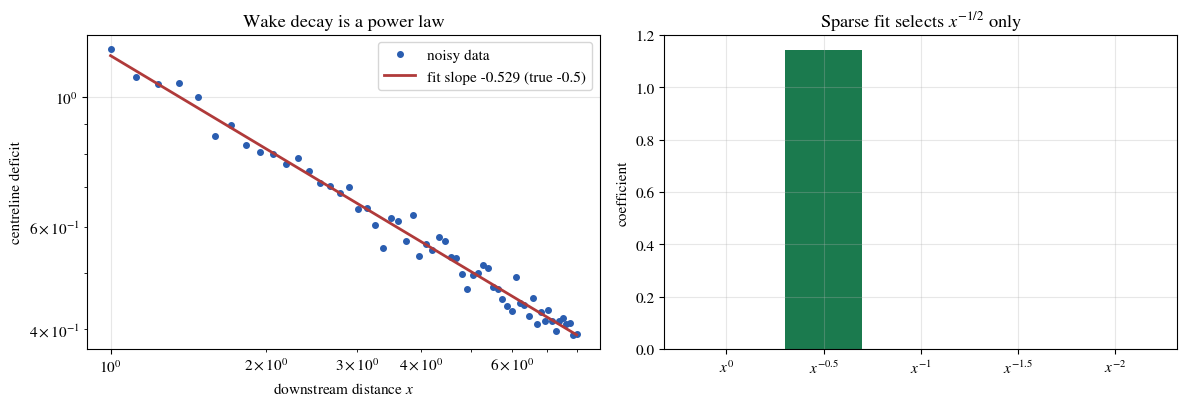

log-log exponent -0.529 (true -0.5); sparse coeffs {'$x^{0}$': np.float64(0.0), '$x^{-0.5}$': np.float64(1.144), '$x^{-1}$': np.float64(0.0), '$x^{-1.5}$': np.float64(0.0), '$x^{-2}$': np.float64(0.0)}


In [3]:
U, nu_t = U_INF, NU_T; D = nu_t/U
x = np.linspace(X_MIN, X_MAX, N_X)
d_true = 1.0/np.sqrt(4*np.pi*D*x)                      # centreline deficit ~ x^-1/2
d_obs = d_true*(1 + WAKE_NOISE*np.random.randn(len(x)))     # multiplicative measurement noise

# log-log exponent fit
slope, intercept = np.polyfit(np.log(x), np.log(d_obs), 1)
# sparse power-law library
powers = [0.0, -0.5, -1.0, -1.5, -2.0]
Theta = np.stack([x**p for p in powers], 1)
Xi = stlsq(Theta, d_obs, lam=LAM_WAKE)
labels = [f'$x^{{{p:g}}}$' for p in powers]

def plot_wind_sindy_decay():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].loglog(x, d_obs, 'C0o', ms=4, label='noisy data')
    ax[0].loglog(x, np.exp(intercept)*x**slope, 'C3', lw=2, label=f'fit slope {slope:.3f} (true -0.5)')
    ax[0].set(xlabel='downstream distance $x$', ylabel='centreline deficit', title='Wake decay is a power law'); ax[0].legend()
    ax[1].bar(range(len(powers)), Xi, color=['C2' if p == -0.5 else '0.7' for p in powers])
    ax[1].set_xticks(range(len(powers))); ax[1].set_xticklabels(labels)
    ax[1].set(ylabel='coefficient', title='Sparse fit selects $x^{-1/2}$ only')
    plt.tight_layout()

save_dual(plot_wind_sindy_decay, 'wind_sindy_decay', FIG)
plt.show()
print(f'log-log exponent {slope:.3f} (true -0.5); sparse coeffs', {l: round(c, 3) for l, c in zip(labels, Xi)})

## 2. Noise robustness by ensembling

With noisier measurements a single fit can wobble. Bootstrapping the data and refitting reports each
term's inclusion frequency and a coefficient distribution: the $x^{-1/2}$ term is selected almost
every time, the spurious ones rarely.

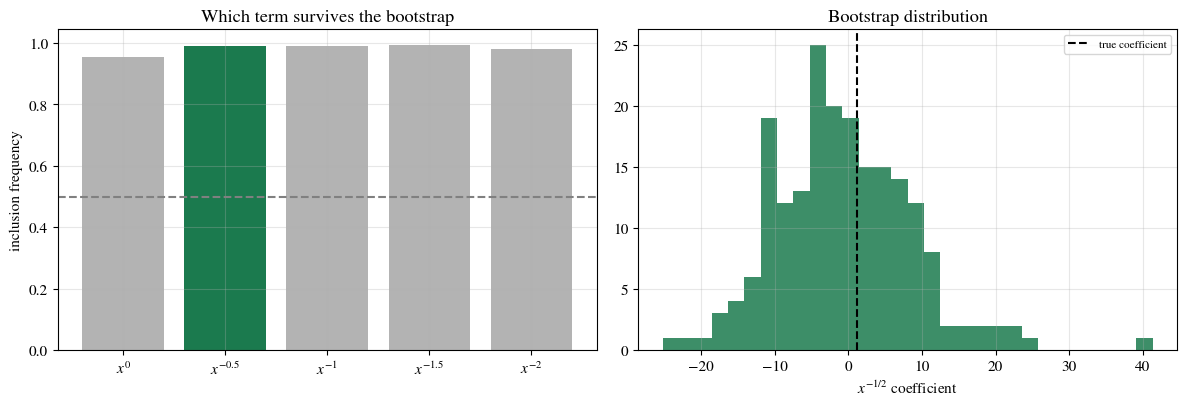

inclusion of x^-1/2: 0.99


In [4]:
B = ENS_B; m = len(x); incl = np.zeros(len(powers)); coefs = []
d_noisy = d_true*(1 + ENS_NOISE*np.random.randn(m))
for b in range(B):
    idx = np.random.choice(m, m, replace=True)
    Xb = stlsq(Theta[idx], d_noisy[idx], lam=ENS_LAM)
    incl += (np.abs(Xb) > 1e-6); coefs.append(Xb)
incl /= B; coefs = np.array(coefs)
j = powers.index(-0.5)

def plot_wind_sindy_ensemble():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].bar(range(len(powers)), incl, color=['C2' if p == -0.5 else '0.7' for p in powers])
    ax[0].set_xticks(range(len(powers))); ax[0].set_xticklabels(labels); ax[0].axhline(0.5, ls='--', c='gray')
    ax[0].set(ylabel='inclusion frequency', title='Which term survives the bootstrap')
    ax[1].hist(coefs[:, j], 30, color='C2', alpha=0.85)
    ax[1].axvline(1.0/np.sqrt(4*np.pi*D), ls='--', c='k', label='true coefficient')
    ax[1].set(xlabel='$x^{-1/2}$ coefficient', title='Bootstrap distribution'); ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_wind_sindy_ensemble, 'wind_sindy_ensemble', FIG)
plt.show()
print('inclusion of x^-1/2:', round(incl[j], 2))

## 3. Closing the loop: discover the erosion law from a learned correction

A hybrid model of the turbine has learned the torque lost to blade erosion as a network correction
$f_{\boldsymbol\theta}(\omega,v)$ that we could plot but not name. (Here $\lambda$ is the tip-speed ratio
$\omega R/v$, not the STLSQ threshold.) Converting it to the fractional $C_p$ deficit and sampling over tip-speed
ratio, sparse regression on a polynomial library $\{1,\lambda,\lambda^2,\lambda^3\}$ recovers the
modelled erosion law $\delta(\lambda)=0.015\,\lambda$ --- a black-box correction turned into an
equation, the maintenance model an engineer can read.

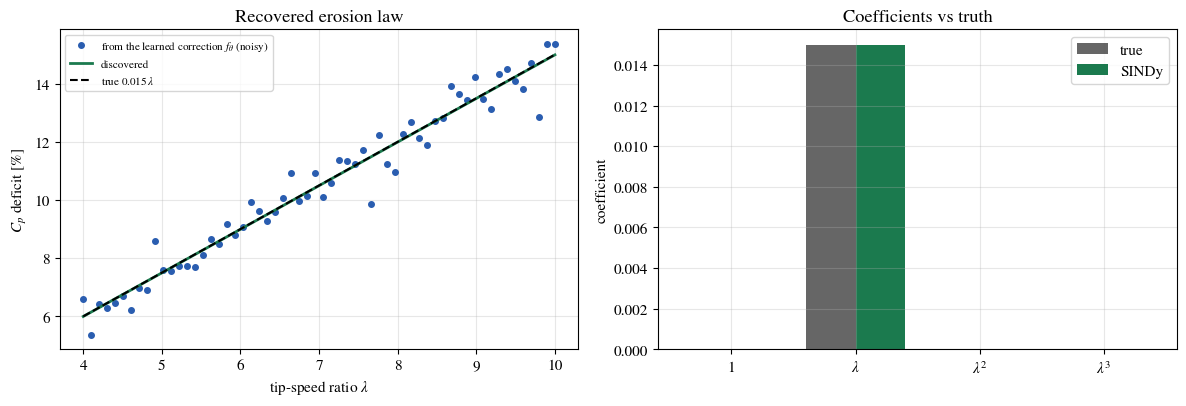

discovered erosion slope (lambda term): 0.015  true 0.015


In [5]:
def erosion(lam): return EROSION_SLOPE*lam                  # the true (modelled) erosion law
rng = np.random.default_rng(3)
lam = np.linspace(4, 10, 60)
delta_obs = erosion(lam)*(1 + EROSION_NOISE*rng.standard_normal(len(lam)))   # sampled from the learned correction, noisy
poly = [0, 1, 2, 3]; Thp = np.stack([lam**p for p in poly], 1)
Xip = stlsq(Thp, delta_obs, lam=LAM_EROSION)

def plot_wind_sindy_loop():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(lam, 100*delta_obs, 'C0o', ms=4, label='from the learned correction $f_\\theta$ (noisy)')
    ax[0].plot(lam, 100*(Thp@Xip), 'C2', lw=2, label='discovered')
    ax[0].plot(lam, 100*erosion(lam), '--', color=fg(), lw=1.5, label='true $0.015\\,\\lambda$')
    ax[0].set(xlabel='tip-speed ratio $\\lambda$', ylabel='$C_p$ deficit [%]', title='Recovered erosion law'); ax[0].legend(fontsize=8)
    plabels = ['$1$', '$\\lambda$', '$\\lambda^2$', '$\\lambda^3$']
    truec = [0, 0.015, 0, 0]
    ax[1].bar(np.arange(4)-0.2, truec, 0.4, label='true', color=fg(), alpha=0.6)
    ax[1].bar(np.arange(4)+0.2, Xip, 0.4, label='SINDy', color='C2')
    ax[1].set_xticks(range(4)); ax[1].set_xticklabels(plabels); ax[1].set(ylabel='coefficient', title='Coefficients vs truth'); ax[1].legend()
    plt.tight_layout()

save_dual(plot_wind_sindy_loop, 'wind_sindy_loop', FIG)
plt.show()
print('discovered erosion slope (lambda term):', round(Xip[1], 4), ' true 0.015')

**Takeaways.** Sparse regression recovers the wake's $x^{-1/2}$ decay law from noisy
measurements (with ensembling for uncertainty), and --- closing the hybrid loop --- it reads the blade
erosion law $\delta\propto\lambda$ straight off the learned correction. The same data $\to$
black box $\to$ correction $\to$ equation arc that ran through the vessel runs through the wind
domain: discovery turns learned corrections into interpretable, reusable physics --- here, a
quantitative maintenance model.